In [7]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

from skimage.metrics import structural_similarity as ssim

# Dataset path
root = Path(r"D:\AMME5710_Major_Project\dataset")
split = "train"

# Select sample
defect_type = "line"
sample_index = 0

files = sorted(
    (root / split / "B").glob(f"{defect_type}_*.png")
)

if not files:
    raise FileNotFoundError("No matching images found.")

filename = files[sample_index].name

print("Selected image:", filename)


Selected image: line_proofrog_a4pera_back_00010_0011.png


In [8]:
# Read images in grayscale
A = cv2.imread(
    str(root / split / "A" / filename),
    cv2.IMREAD_GRAYSCALE
)

B = cv2.imread(
    str(root / split / "B" / filename),
    cv2.IMREAD_GRAYSCALE
)

# Ground Truth
GT = cv2.imread(
    str(root / split / "OUT" / filename),
    cv2.IMREAD_GRAYSCALE
)

if A is None or B is None or GT is None:
    raise FileNotFoundError("Failed to read images.")

if A.shape != B.shape or A.shape != GT.shape:
    raise ValueError("Image dimensions do not match.")

gt_mask = GT > 0

print("Image shape:", A.shape)
print("GT shape:", GT.shape)


Image shape: (256, 256)
GT shape: (256, 256)


In [9]:
# Calculate SSIM
ssim_score, ssim_map = ssim(
    A,
    B,
    data_range=255,
    win_size=7,
    full=True
)

# Convert similarity into dissimilarity
diff_ssim = np.clip(
    (1.0 - ssim_map) / 2.0,
    0.0,
    1.0
)

# Initial threshold
T_ssim = 0.10

# Predicted Mask
pred_ssim = diff_ssim > T_ssim

# Evaluation
TP = np.count_nonzero(pred_ssim & gt_mask)
FP = np.count_nonzero(pred_ssim & ~gt_mask)
FN = np.count_nonzero(~pred_ssim & gt_mask)

precision = TP / (TP + FP) if TP + FP > 0 else 0
recall = TP / (TP + FN) if TP + FN > 0 else 0

f1 = (
    2 * TP / (2 * TP + FP + FN)
    if 2 * TP + FP + FN > 0 else 0
)

iou = (
    TP / (TP + FP + FN)
    if TP + FP + FN > 0 else 0
)

print(f"Mean SSIM: {ssim_score:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"IoU:       {iou:.4f}")


Mean SSIM: 0.8140
Precision: 0.0134
Recall:    0.9511
F1-score:  0.0265
IoU:       0.0134


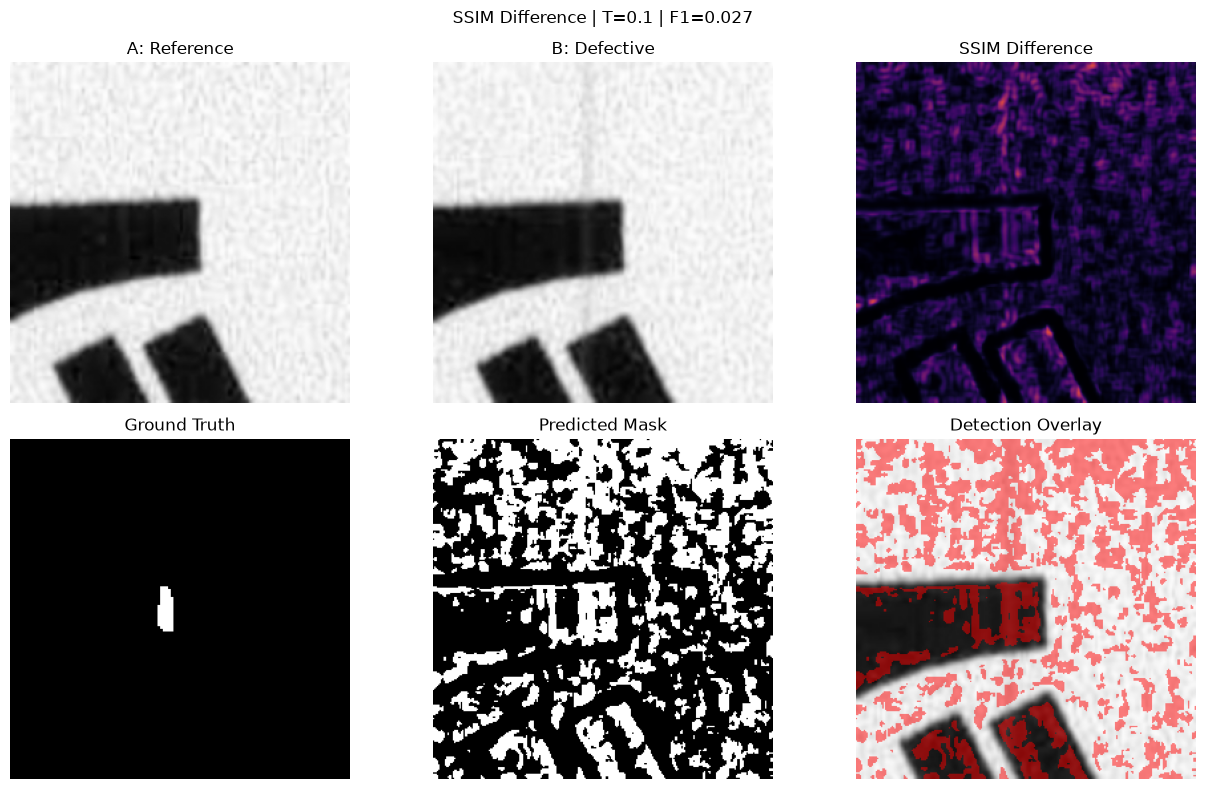

In [10]:
# Convert to RGB for visualisation
A_rgb = cv2.cvtColor(A, cv2.COLOR_GRAY2RGB)
B_rgb = cv2.cvtColor(B, cv2.COLOR_GRAY2RGB)

# Predicted Mask Overlay
overlay = B_rgb.copy()

overlay[pred_ssim] = (
    0.5 * B_rgb[pred_ssim] +
    0.5 * np.array([255, 0, 0])
).astype(np.uint8)

fig, axes = plt.subplots(2, 3, figsize=(13, 8))

images = [
    A,
    B,
    diff_ssim,
    gt_mask,
    pred_ssim,
    overlay
]

titles = [
    "A: Reference",
    "B: Defective",
    "SSIM Difference",
    "Ground Truth",
    "Predicted Mask",
    "Detection Overlay"
]

for ax, img, title in zip(axes.flat, images, titles):

    if title == "SSIM Difference":
        ax.imshow(img, cmap="inferno", vmin=0, vmax=1)

    elif img.ndim == 2:
        ax.imshow(img, cmap="gray")

    else:
        ax.imshow(img)

    ax.set_title(title)
    ax.axis("off")

plt.suptitle(
    f"SSIM Difference | T={T_ssim} | F1={f1:.3f}"
)

plt.tight_layout()
plt.show()


In [11]:
thresholds_ssim = np.arange(0.05, 0.51, 0.05)

for t in thresholds_ssim:
    pred = diff_ssim > t

    tp = np.count_nonzero(pred & gt_mask)
    fp = np.count_nonzero(pred & ~gt_mask)
    fn = np.count_nonzero(~pred & gt_mask)

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0
    f1 = 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0

    print(
        f"T={t:.2f} | "
        f"P={precision:.4f} | "
        f"R={recall:.4f} | "
        f"F1={f1:.4f}"
    )

T=0.05 | P=0.0075 | R=1.0000 | F1=0.0149
T=0.10 | P=0.0134 | R=0.9511 | F1=0.0265
T=0.15 | P=0.0180 | R=0.6092 | F1=0.0349
T=0.20 | P=0.0130 | R=0.1983 | F1=0.0245
T=0.25 | P=0.0067 | R=0.0431 | F1=0.0117
T=0.30 | P=0.0000 | R=0.0000 | F1=0.0000
T=0.35 | P=0.0000 | R=0.0000 | F1=0.0000
T=0.40 | P=0.0000 | R=0.0000 | F1=0.0000
T=0.45 | P=0.0000 | R=0.0000 | F1=0.0000
T=0.50 | P=0.0000 | R=0.0000 | F1=0.0000


Original SSIM F1: 0.0349
Smoothed SSIM F1: 0.0519


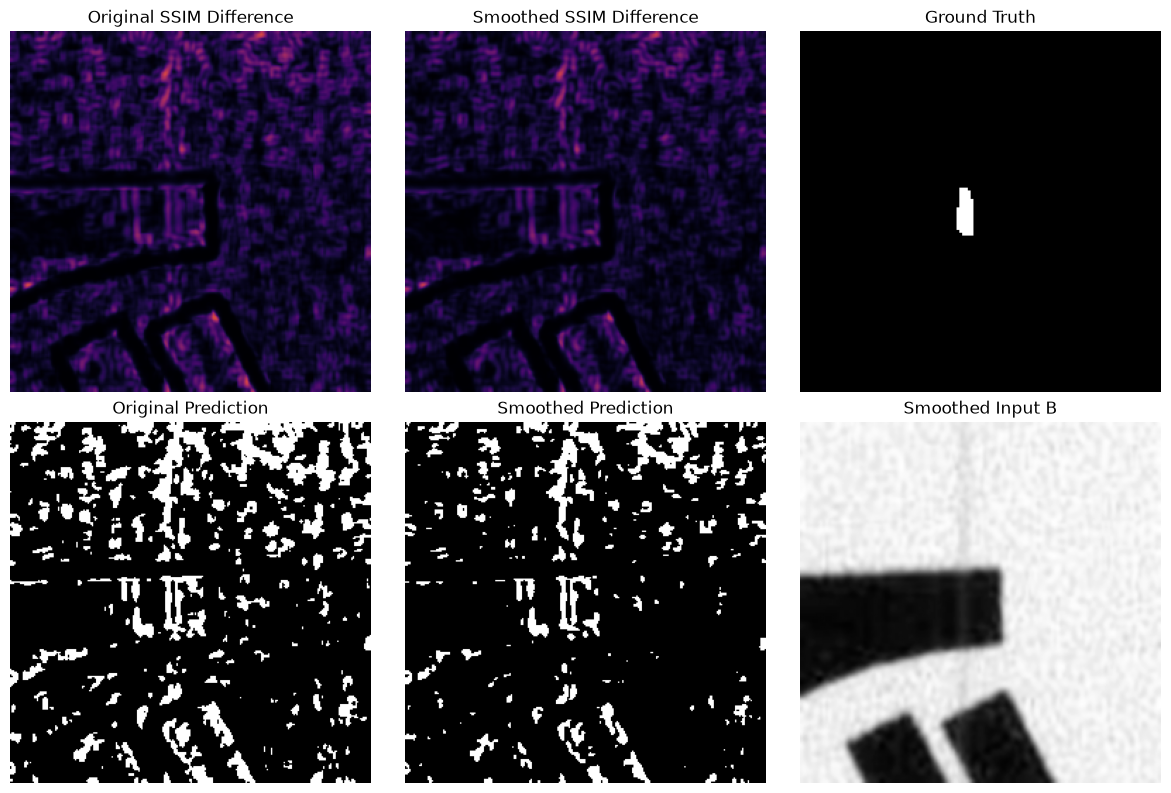

In [12]:
# Compare original SSIM and Gaussian-smoothed SSIM

# 1. Apply Gaussian smoothing
A_blur = cv2.GaussianBlur(A, (3, 3), 0.8)
B_blur = cv2.GaussianBlur(B, (3, 3), 0.8)

# 2. Calculate SSIM on smoothed images
_, ssim_map_blur = ssim(
    A_blur,
    B_blur,
    data_range=255,
    win_size=7,
    full=True
)

# 3. Convert to difference map
diff_ssim_blur = np.clip(
    (1.0 - ssim_map_blur) / 2.0,
    0.0,
    1.0
)

# 4. Use same threshold for comparison
T_compare = 0.15

pred_original = diff_ssim > T_compare
pred_blur = diff_ssim_blur > T_compare

# 5. Calculate F1
def compute_f1(pred, gt):
    tp = np.count_nonzero(pred & gt)
    fp = np.count_nonzero(pred & ~gt)
    fn = np.count_nonzero(~pred & gt)

    return 2 * tp / (2 * tp + fp + fn) if (2*tp + fp + fn) > 0 else 0

print("Original SSIM F1:",
      round(compute_f1(pred_original, gt_mask), 4))

print("Smoothed SSIM F1:",
      round(compute_f1(pred_blur, gt_mask), 4))

# 6. Visual comparison
fig, axes = plt.subplots(2, 3, figsize=(12, 8))

images = [
    diff_ssim,
    diff_ssim_blur,
    gt_mask,
    pred_original,
    pred_blur,
    B_blur
]

titles = [
    "Original SSIM Difference",
    "Smoothed SSIM Difference",
    "Ground Truth",
    "Original Prediction",
    "Smoothed Prediction",
    "Smoothed Input B"
]

for ax, img, title in zip(axes.flat, images, titles):
    if title in ["Original SSIM Difference",
                 "Smoothed SSIM Difference"]:
        ax.imshow(img, cmap="inferno", vmin=0, vmax=1)
    else:
        ax.imshow(img, cmap="gray")
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()
